# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

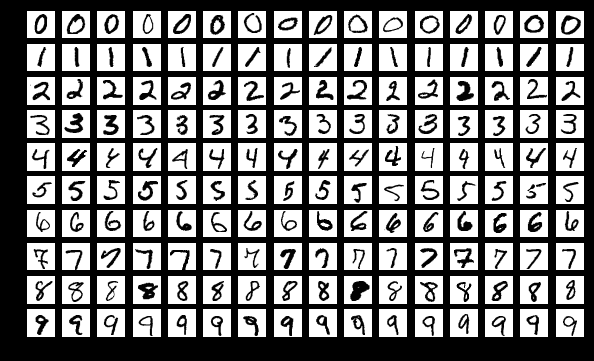

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [ ]:
# %pip install torch

In [8]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


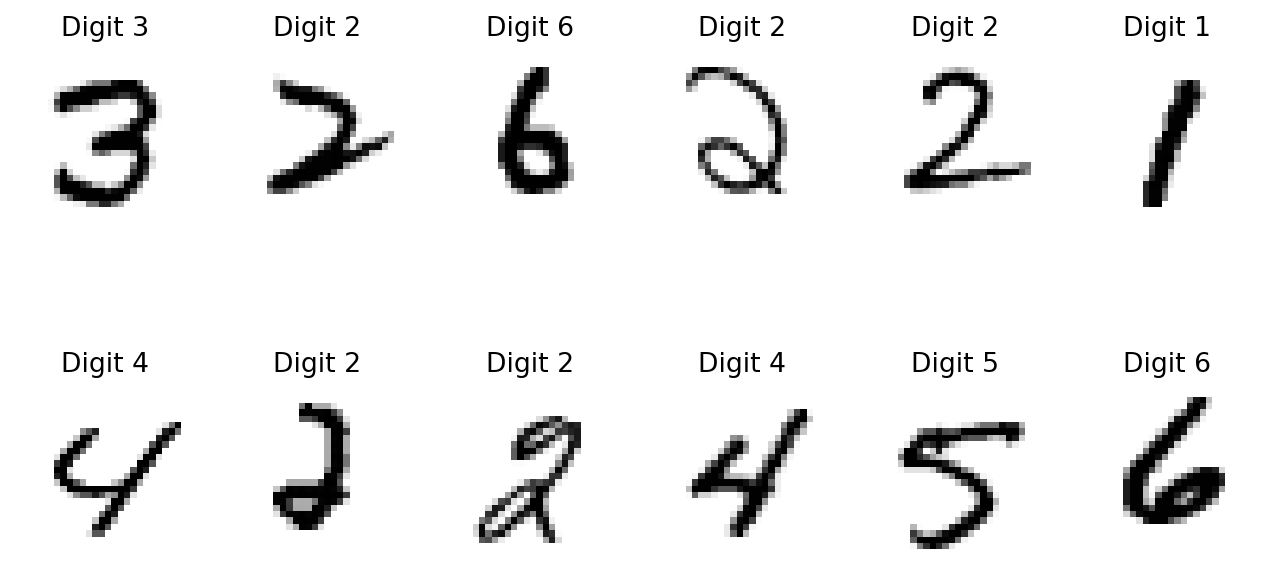

In [9]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

# SVM

First try is with old-school SVM. This code is very slow compared to the Deep Learning approaches, and the result is still not that good. The long run-time with the bad fit at the same time really goes to show how why Deep Learning approaches are the preferred architecture for modern Computer Vision.

In [ ]:
#MNIST with SV
pca = PCA(n_components=90) #we use PCA to reduce number of features to 90. It is done so our training doesn't take too much time 
#(90 was chosen by trial and error approach, in this case we get relatively good result with quick training)
images_scaled = StandardScaler().fit_transform(images) #standardize each pixel to mean=0 and std=1

images_reduced = pca.fit_transform(images_scaled) #reduce dimensionality with PCA

print(pca.explained_variance_ratio_)
print(sum(pca.explained_variance_ratio_)) #in the output we can see that our 90 features keep ~68% of the information so for that big reduction it's okay

[0.05642719 0.04041226 0.03738273 0.02893    0.02520752 0.02192549
 0.01914282 0.01740684 0.01532232 0.01396087 0.01342175 0.01201421
 0.01113962 0.01090582 0.01027986 0.00994955 0.00931255 0.00919635
 0.008886   0.00863195 0.00821741 0.00798417 0.00762573 0.00742315
 0.0071657  0.00689314 0.00681399 0.00654588 0.00627293 0.00610345
 0.00597261 0.00589304 0.00567358 0.00559358 0.00552473 0.00534443
 0.00527593 0.00515841 0.00505498 0.00477438 0.00476312 0.00465155
 0.00453454 0.00445757 0.00442313 0.00437877 0.00437294 0.00427724
 0.00424808 0.00418524 0.00404059 0.00396258 0.00393176 0.00390562
 0.00386444 0.00377501 0.00373883 0.00368328 0.00360377 0.0035637
 0.00349289 0.00344527 0.00343239 0.00341    0.00334463 0.00332107
 0.00329803 0.00319433 0.0031711  0.00315431 0.00309941 0.00305782
 0.00305095 0.0030396  0.00296635 0.00292958 0.00291295 0.00290232
 0.00288608 0.00287022 0.00284514 0.00281524 0.00279245 0.00278629
 0.00278233 0.00276733 0.0027542  0.00272901 0.0026874  0.00268

In [11]:
X_train, X_test, y_train, y_test = train_test_split(images_reduced, targets, test_size=0.2) #splitting data into train and test where test size is 20% of the whole dataset
print(X_train.shape)
print(X_test.shape)

(56000, 90)
(14000, 90)


In [12]:
clf = svm.LinearSVC(penalty='l2', loss='squared_hinge', random_state=42, max_iter=10000)
clf.fit(X_train, y_train) #now we train our SVM model

#90% score on the test set with SVM is a good result looking at the big reduction of the number features
print(f'Train score {clf.score(X_train, y_train)}, Test score {clf.score(X_test, y_test)}')

Train score 0.9054464285714285, Test score 0.9051428571428571


As you will see this test score is significantly higher with Deep Learning approaches.

# Deep learning approaches

Our first try is with a simple MLP model. This model is in general not well-suited for image analysis and prediction for several reasons. First of all the MLP architecture is not invariant to shifts in the image (all pixels shifted 1 to the left for example). We humans clearly see that a 5 is still a 5 if its shifted, but the general shift in the image is a huge change of the input. However with MNIST the images are very centered, and the ability to learn this kind of invariance is not hugely important. The second big problem in MLP is that it has to learn pixel-to-pixel relations (edges and such) for every part of the image separately, this is a huge waste of parameters, and often means a MLP needs many more parameters than a comparable scoring CNN. However testing and running the code has shown that these concerns are not very important on the MNIST dataset, as our MLP reaches over 98% accuracy on the test dataset.

In [13]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


# MLP model
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, num_classes):
        super(NeuralNet, self).__init__()

        self.input_size = input_size
        
        # First hidden layer: z1 = W1*x + b1.
        self.l1 = nn.Linear(input_size, hidden_size1)
        # Normalize activations using batch statistics during training.
        # During evaluation, use the running statistics learned in training.
        self.bn1 = nn.BatchNorm1d(hidden_size1)
        # ReLU(z) = max(0, z): allows the network to learn nonlinear patterns.
        self.relu1 = nn.ReLU()

        # Second hidden layer: z2 = W2*h1 + b2.
        self.l2 = nn.Linear(hidden_size1, hidden_size2)
        self.bn2 = nn.BatchNorm1d(hidden_size2)
        self.relu2 = nn.ReLU()

        # Output layer: one score (logit) for each digit from 0 to 9.
        self.l3 = nn.Linear(hidden_size2, num_classes)

    def forward(self, x):
        # Pass the batch through the first hidden layer.
        out = self.l1(x)
        out = self.bn1(out)
        out = self.relu1(out)

        # Pass the result through the second hidden layer.
        out = self.l2(out)
        out = self.bn2(out)
        out = self.relu2(out)

        # Return raw scores, with shape [batch_size, 10].
        # No softmax is needed here: CrossEntropyLoss handles it internally.
        out = self.l3(out)
        return out


# Train the model
def train_model(model, optimizer, data_loader, loss_module,
                device, num_epochs=5):

    model.train()
    n_total_steps = len(data_loader)

    for epoch in range(num_epochs):
        for i, (data_inputs, data_labels) in enumerate(data_loader):
            # Images are already flattened to 784 pixels.
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            optimizer.zero_grad()

            # Forward pass
            outputs = model(data_inputs)
            loss = loss_module(outputs, data_labels)

            # Backward pass and update weights
            loss.backward()
            optimizer.step()

            if (i + 1) % 100 == 0:
                print(
                    f'Epoch [{epoch + 1}/{num_epochs}], '
                    f'Step [{i + 1}/{n_total_steps}], '
                    f'Loss: {loss.item():.4f}'
                )


# Evaluate the model
def eval_model(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for data_inputs, data_labels in data_loader:
            data_inputs = data_inputs.to(device)
            data_labels = data_labels.to(device)

            outputs = model(data_inputs)

            # Select the highest-scoring digit for each image.
            # Dimension 1 contains the 10 digit scores.
            _, predicted = torch.max(outputs, 1)

            total += data_labels.size(0)
            correct += (predicted == data_labels).sum().item()

    accuracy = correct / total

    print(
        f'Accuracy of the classifier on the {total} test images: '
        f'{100 * accuracy:.2f}%'
    )


# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters- Whole architecture: 784 inputs -> 500 -> 500 -> 10 outputs
input_size = 28 * 28
# 2 hidden layers of 500 neurons
hidden_size1 = 500
hidden_size2 = 500
# classes  = number of digits
num_classes = 10
# epochs = 8 -> accuracy 97,7%, epochs = 15 -> accuracy 98.39%
num_epochs = 15
batch_size = 64
learning_rate = 0.001


# Convert the already loaded data into tensors.
# Scale pixel values from [0, 255] to [-1, 1].
image_tensors = torch.tensor(images, dtype=torch.float32)
image_tensors = image_tensors / 127.5 - 1.0

# OpenML labels are strings; cross-entropy requires integer labels.
target_tensors = torch.tensor(
    targets.astype(np.int64),
    dtype=torch.long
)


# Standard MNIST split: 60,000 training and 10,000 test images.
train_dataset = TensorDataset(
    image_tensors[:60000],
    target_tensors[:60000]
)

test_dataset = TensorDataset(
    image_tensors[60000:],
    target_tensors[60000:]
)


# Data loaders
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False
)


# Initialize the model
model = NeuralNet(
    input_size, hidden_size1, hidden_size2, num_classes
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


# Train and evaluate
train_model(
    model, optimizer, train_loader, criterion, device, num_epochs
)

eval_model(model, test_loader, device)


# Classify one image from the MNIST test dataset
image, true_label = test_dataset[0]

model.eval()
with torch.no_grad():
    output = model(image.reshape(1, input_size).to(device))
    predicted_label = output.argmax(dim=1).item()

# print(
#     f'True digit: {true_label.item()}, '
#     f'predicted digit: {predicted_label}'
# )

Epoch [1/15], Step [100/938], Loss: 0.1575
Epoch [1/15], Step [200/938], Loss: 0.1287
Epoch [1/15], Step [300/938], Loss: 0.0826
Epoch [1/15], Step [400/938], Loss: 0.1490
Epoch [1/15], Step [500/938], Loss: 0.2244
Epoch [1/15], Step [600/938], Loss: 0.0670
Epoch [1/15], Step [700/938], Loss: 0.1827
Epoch [1/15], Step [800/938], Loss: 0.0502
Epoch [1/15], Step [900/938], Loss: 0.0626
Epoch [2/15], Step [100/938], Loss: 0.0277
Epoch [2/15], Step [200/938], Loss: 0.0153
Epoch [2/15], Step [300/938], Loss: 0.0407
Epoch [2/15], Step [400/938], Loss: 0.0345
Epoch [2/15], Step [500/938], Loss: 0.0672
Epoch [2/15], Step [600/938], Loss: 0.0119
Epoch [2/15], Step [700/938], Loss: 0.0779
Epoch [2/15], Step [800/938], Loss: 0.1576
Epoch [2/15], Step [900/938], Loss: 0.0080
Epoch [3/15], Step [100/938], Loss: 0.0435
Epoch [3/15], Step [200/938], Loss: 0.0936
Epoch [3/15], Step [300/938], Loss: 0.1086
Epoch [3/15], Step [400/938], Loss: 0.0303
Epoch [3/15], Step [500/938], Loss: 0.0303
Epoch [3/15

As you see our MPL preforms quite well, but this is with ~648,000 parameters, which is a lot for such as simple task.

Now comes the CNN approach

In [14]:
import numpy as np
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split

/opt/homebrew/Caskroom/miniforge/base/envs/pfas/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
device = None
if torch.backends.mps.is_available():
    print('MPS is available')
    device = torch.device('mps')
else:
    print("The code will run on CPU. Go to Edit->Notebook Settings and choose GPU as the hardware accelerator")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

MPS is available
mps


In [16]:
#defining CNN network for MNIST dataset
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.convolutional = nn.Sequential(
            #padding='same' adds padding so the spatial dimension's size after convolution stays the same
            nn.Conv2d(1, 16, 3, padding='same'), nn.ReLU(),
            nn.MaxPool2d(2),                       # 14x14
            nn.Conv2d(16, 32, 3, padding='same'), nn.ReLU(),
            nn.MaxPool2d(2),                       # 7x7
            nn.Conv2d(32, 64, 3, padding='same'), nn.ReLU(),
            nn.MaxPool2d(2),                       # 3x3
            #CNN layer outputs a 3*3*64 feature map
                )

        #finishing neural network with fully connected layers and 10 outputs, where each output is the raw score (logit) for one digit class
        self.fully_connected = nn.Sequential(
                nn.Linear(3*3*64, 128),
                nn.ReLU(),
                nn.Linear(128, 10))
    
    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1) #flattening so the conv output can be fed into the fully connected layers
        x = self.fully_connected(x)
        return x

In [ ]:
X_cnn = images.reshape(-1, 1, 28, 28).astype('float32') / 255.0 #reshaping images to nx1x28x28 and normalizing them to values [0;1]
y_cnn = targets.astype('int64')

X_train_cnn, X_test_cnn, y_train_cnn, y_test_cnn = train_test_split(
    X_cnn, y_cnn, test_size=0.2, random_state=42) #splitting data the same process as before

# Convert the already loaded data into tensors.
trainset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_train_cnn), torch.from_numpy(y_train_cnn))
testset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_test_cnn), torch.from_numpy(y_test_cnn))

#defining batch size and dataloaders for the train and test sets
batch_size = 64
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [18]:
model = Network().to(device) #converting model to the desired device
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #we use Adam optimizer with learning rate 0.001
criterion = nn.CrossEntropyLoss() #we use CrossEntropy as our loss function

#training loop
n_epochs = 10
for epoch in range(n_epochs):
    model.train()
    train_loss = 0
    correct = 0
    for X_batch, y_batch in tqdm(train_loader):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device) #changing tensors to desired device

        optimizer.zero_grad() #setting gradient to 0
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0) #calculating total loss
        correct += (outputs.argmax(dim=1) == y_batch).sum().item() #accumulates count of correct predictions (accuracy computed below)

    train_acc = correct / len(trainset)
    print(f'Epoch {epoch+1}/{n_epochs}: loss={train_loss/len(trainset):.4f}  train_acc={train_acc:.4f}')


test_loss = 0
correct = 0
#testing the model performance
model.eval()
with torch.no_grad(): #stops autograd from building a computation graph  
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        test_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

test_acc = correct / len(testset)
print(f"Test loss: {test_loss/len(testset):.4f}, accuracy: {test_acc:.4f}")

100%|██████████| 875/875 [00:07<00:00, 115.04it/s]


Epoch 1/10: loss=0.2366  train_acc=0.9242


100%|██████████| 875/875 [00:06<00:00, 127.29it/s]


Epoch 2/10: loss=0.0639  train_acc=0.9798


100%|██████████| 875/875 [00:07<00:00, 122.70it/s]


...

Epoch 8/10: loss=0.0167  train_acc=0.9946


100%|██████████| 875/875 [00:06<00:00, 128.28it/s]


Epoch 9/10: loss=0.0148  train_acc=0.9948


100%|██████████| 875/875 [00:06<00:00, 125.41it/s]


Epoch 10/10: loss=0.0123  train_acc=0.9961
Test loss: 0.0409, accuracy: 0.9879


This shows the power of the CNN architecture. We get a slightly better performance compared to the MLP, but we go from ~650K parameters to ~100K parameters, so our model runs ~6.5x faster and even with a slightly better performance while being so much faster! CNN rocks.

# Face challenge with CNN

In [19]:
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

In [20]:
X = lfw_people.data
y = lfw_people.target

print(X.shape)

(1288, 1850)


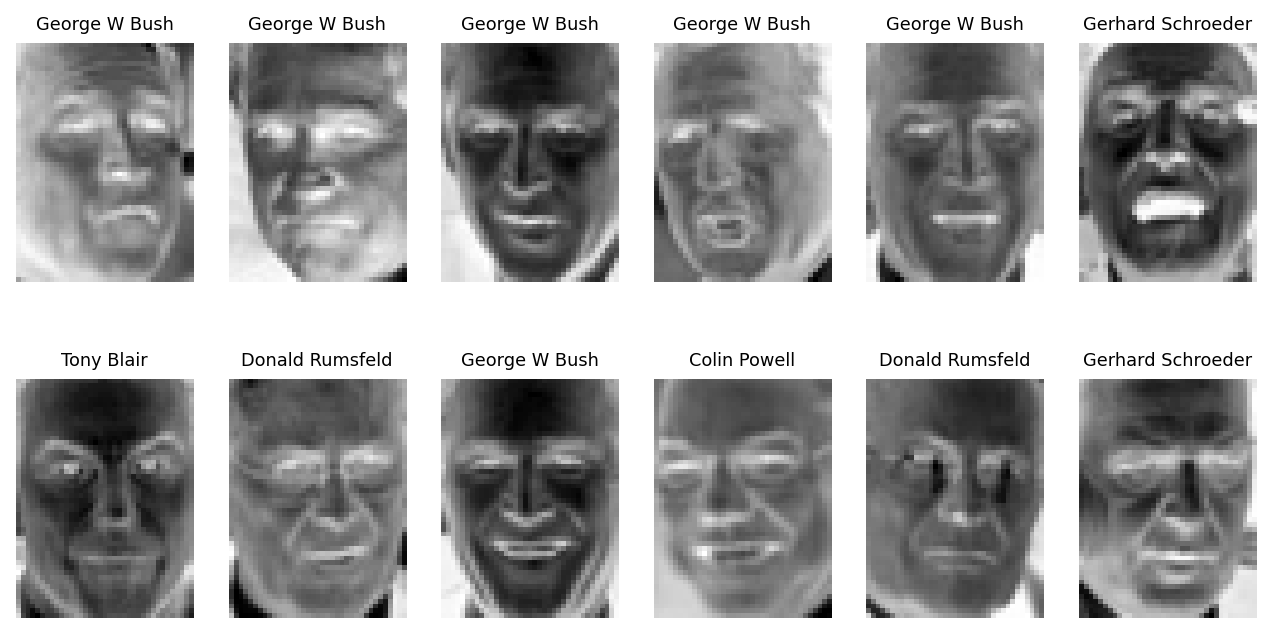

In [21]:
#this function was generated with claude code in order to display images similarly as with MNIST dataset
def show_some_faces(images, targets, target_names, h, w, sample_size=24, title_text='{}'):
    '''
    Visualize random faces in a grid plot
    images - array of flattened faces [:, h*w]
    targets - integer class labels
    target_names - array mapping label index -> person name
    h, w - original (unflattened) image height/width
    '''
    nsamples = sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))

    plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        plt.imshow(image.reshape(h, w), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(target_names[label]), fontsize=8)
    plt.show()

h, w = lfw_people.images.shape[1:]
show_some_faces(X, y, lfw_people.target_names, h, w, 12)

In [ ]:
h, w = lfw_people.images.shape[1:] #extracting shapes of the images (height, width)
n_classes = len(lfw_people.target_names)

# reshaping data to n x 1 x h x w (the 1 is the channel dim Conv2d expects)
# lfw_people.data is already scaled to [0, 1] by sklearn
X_faces = X.reshape(-1, 1, h, w).astype('float32')
y_faces = y.astype('int64')

# splitting data as usual, the addition is stratify=y_faces which keeps faces evenly distributed becasue our dataset is very small 
X_train_faces, X_test_faces, y_train_faces, y_test_faces = train_test_split( 
    X_faces, y_faces, test_size=0.2, random_state=42, stratify=y_faces)

#In order to not overfit to the samples we make more data by doing slight random shifts
face_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
])

# TensorDataset (used below for the test set) can't apply a transform, so this custom Dataset exists specifically to support the random augmentation above on the training set
class FaceDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        if self.transform is not None:
            x = self.transform(x)
        return x, self.y[idx]

face_trainset = FaceDataset(
    torch.from_numpy(X_train_faces), torch.from_numpy(y_train_faces),
    transform=face_train_transform)

# no augmentation at test time so we can measure real performance
face_testset = torch.utils.data.TensorDataset(
    torch.from_numpy(X_test_faces), torch.from_numpy(y_test_faces))

# smaller batch size than MNIST's, since this training set is muchsmaller (~1030 images vs 56,000)
face_batch_size = 16
face_train_loader = DataLoader(face_trainset, batch_size=face_batch_size, shuffle=True)
face_test_loader = DataLoader(face_testset, batch_size=face_batch_size, shuffle=False)

In [23]:
#defining CNN for face dataset
class FaceNetwork(nn.Module):
    def __init__(self, h, w, n_classes):
        super(FaceNetwork, self).__init__()
        self.convolutional = nn.Sequential(
                nn.Conv2d(1, 8, (3,3), padding='same'),
                nn.BatchNorm2d(8),  # normalizes activations per channel - stabilizes and speeds up training
                nn.ReLU(),
                nn.Conv2d(8, 8, (3,3), padding='same'),
                nn.BatchNorm2d(8),
                nn.ReLU(),
                nn.MaxPool2d((2,2)),
                nn.Conv2d(8, 16, (3,3), padding='same'),
                nn.BatchNorm2d(16),
                nn.ReLU(),
                nn.Conv2d(16, 32, (3,3), padding='same'),
                nn.BatchNorm2d(32),
                nn.ReLU(),
                )

        # one MaxPool2d(2,2) above halves each spatial dim, so the
        # flattened feature map is 32 channels x (h//2) x (w//2)
        flat_dim = 32 * (h // 2) * (w // 2)
        self.fully_connected = nn.Sequential(
                nn.Linear(flat_dim, 500),
                nn.ReLU(),
                nn.Dropout(0.5),  # because the dataset is so small this protects network before overfitting
                nn.Linear(500, n_classes))

    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

In [24]:
face_model = FaceNetwork(h, w, n_classes).to(device)
# weight_decay (L2 regularization) and label_smoothing are both extra regularization added 
face_optimizer = torch.optim.Adam(face_model.parameters(), lr=0.001, weight_decay=1e-4)
face_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# more epochs than on previous dataset because each epoch is much faster here tiny and regularization requires more epochs to converge
n_epochs = 80
for epoch in range(n_epochs):
    start = time.time()
    face_model.train()
    train_loss = 0
    correct = 0
    for X_batch, y_batch in face_train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        face_optimizer.zero_grad()
        outputs = face_model(X_batch)
        loss = face_criterion(outputs, y_batch)
        loss.backward()
        face_optimizer.step()

        train_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

    train_acc = correct / len(face_trainset)
    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{n_epochs}: {elapsed:.1f}s  loss={train_loss/len(face_trainset):.4f}  train_acc={train_acc:.4f}')


test_loss = 0
correct = 0
face_model.eval()
with torch.no_grad():
    for X_batch, y_batch in face_test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = face_model(X_batch)
        loss = face_criterion(outputs, y_batch)

        test_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()

test_acc = correct / len(face_testset)
print(f"Test loss: {test_loss/len(face_testset):.4f}, accuracy: {test_acc:.4f}")

Epoch 1/80: 1.7s  loss=2.6005  train_acc=0.3447
Epoch 2/80: 1.1s  loss=1.6788  train_acc=0.4340
Epoch 3/80: 1.1s  loss=1.5819  train_acc=0.4883
Epoch 4/80: 1.2s  loss=1.4492  train_acc=0.5369
Epoch 5/80: 1.2s  loss=1.3655  train_acc=0.5641
Epoch 6/80: 1.2s  loss=1.2952  train_acc=0.5971
Epoch 7/80: 1.1s  loss=1.2841  train_acc=0.6117
Epoch 8/80: 1.2s  loss=1.2421  train_acc=0.6447
Epoch 9/80: 1.1s  loss=1.2057  train_acc=0.6534
Epoch 10/80: 1.2s  loss=1.1450  train_acc=0.6786
Epoch 11/80: 1.1s  loss=1.1396  train_acc=0.6961
Epoch 12/80: 1.1s  loss=1.1261  train_acc=0.6990
Epoch 13/80: 1.1s  loss=1.1010  train_acc=0.7019
Epoch 14/80: 1.2s  loss=1.0683  train_acc=0.7262
Epoch 15/80: 1.2s  loss=1.0590  train_acc=0.7417
Epoch 16/80: 1.1s  loss=1.0092  train_acc=0.7641
Epoch 17/80: 1.1s  loss=1.0178  train_acc=0.7544
Epoch 18/80: 1.2s  loss=0.9938  train_acc=0.7699
Epoch 19/80: 1.1s  loss=0.9936  train_acc=0.7612
Epoch 20/80: 1.1s  loss=0.9694  train_acc=0.7845
Epoch 21/80: 1.1s  loss=0.948